# Homework – Text Processing and Word Clouds in Python

**Text:** Niccolò Machiavelli, *The Prince* (1532), English translation by W. K. Marriott, from Project Gutenberg.

I chose *The Prince* because it is one of the most important political texts of the early modern period, so I can compare the word cloud with what historians already know about the book.

## Task 1 – Read Text and Work With It

### 1. Load the text from the internet
`urlopen()` opens the URL, `.read()` downloads the content as bytes and `.decode("utf-8")` turns the bytes into readable text (a string).

In [1]:
import urllib.request

url = "https://www.gutenberg.org/cache/epub/1232/pg1232.txt"
response = urllib.request.urlopen(url)
text = response.read().decode("utf-8")

print(len(text), "characters loaded")

307124 characters loaded


### 2. Preview the beginning (slicing)
`text[:400]` shows the first 400 characters. The file starts with a Project Gutenberg header, not with Machiavelli's text.

In [2]:
print(text[:400])

The Project Gutenberg eBook of The Prince
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States


### 3. Keep only *The Prince* itself
The file also has an introduction, a table of contents, two other works by Machiavelli and a licence at the end. `.find()` tells me the position of a piece of text. I find where chapter I really starts (the words appear twice, first in the table of contents, so I search again after the first match) and where the next work starts. Then I slice the text between these two positions.

In [3]:
first = text.find("CHAPTER I.")
start = text.find("CHAPTER I.", first + 1)                  # second match = real chapter I
end = text.rfind("DESCRIPTION OF THE METHODS ADOPTED")       # start of the next work

prince = text[start:end]

print(len(prince), "characters in The Prince")
print(prince[:200])

185166 characters in The Prince
CHAPTER I.
HOW MANY KINDS OF PRINCIPALITIES THERE ARE, AND BY WHAT MEANS THEY ARE
ACQUIRED


All states, all powers, that have held and hold rule over men have been
and are either republics or p


### 4. List all chapters (loop + if)
`.split("\n")` splits the text into lines. The loop visits every line; `if` checks whether the line starts with `"CHAPTER"`. If it does, I print it together with the next line, which is the chapter title.

In [4]:
lines = prince.split("\n")

for i in range(len(lines)):
    if lines[i].startswith("CHAPTER"):
        print(lines[i].strip(), lines[i + 1].strip())

CHAPTER I. HOW MANY KINDS OF PRINCIPALITIES THERE ARE, AND BY WHAT MEANS THEY ARE
CHAPTER II. CONCERNING HEREDITARY PRINCIPALITIES
CHAPTER III. CONCERNING MIXED PRINCIPALITIES
CHAPTER IV. WHY THE KINGDOM OF DARIUS, CONQUERED BY ALEXANDER, DID NOT REBEL
CHAPTER V. CONCERNING THE WAY TO GOVERN CITIES OR PRINCIPALITIES WHICH LIVED UNDER
CHAPTER VI. CONCERNING NEW PRINCIPALITIES WHICH ARE ACQUIRED BY ONE’S OWN ARMS AND
CHAPTER VII. CONCERNING NEW PRINCIPALITIES WHICH ARE ACQUIRED EITHER BY THE ARMS OF
CHAPTER VIII. CONCERNING THOSE WHO HAVE OBTAINED A PRINCIPALITY BY WICKEDNESS
CHAPTER IX. CONCERNING A CIVIL PRINCIPALITY
CHAPTER X. CONCERNING THE WAY IN WHICH THE STRENGTH OF ALL PRINCIPALITIES OUGHT TO
CHAPTER XI. CONCERNING ECCLESIASTICAL PRINCIPALITIES
CHAPTER XII. HOW MANY KINDS OF SOLDIERY THERE ARE, AND CONCERNING MERCENARIES
CHAPTER XIII. CONCERNING AUXILIARIES, MIXED SOLDIERY, AND ONE’S OWN
CHAPTER XIV. THAT WHICH CONCERNS A PRINCE ON THE SUBJECT OF THE ART OF WAR
CHAPTER XV. CONCER

### 5. Split into words and use indexing
`.split()` without anything in the brackets splits at spaces **and** line breaks, so I get a list of words.

In [5]:
words = prince.split()

print(len(words), "words")
print(words[0])        # first word
print(words[-1])       # last word
print(words[:15])      # first 15 words
print(words[-10:])     # last 10 words

32323 words
CHAPTER
1640.
['CHAPTER', 'I.', 'HOW', 'MANY', 'KINDS', 'OF', 'PRINCIPALITIES', 'THERE', 'ARE,', 'AND', 'BY', 'WHAT', 'MEANS', 'THEY', 'ARE']
['dead,', 'Nor', 'in', 'th’', 'Italians’', 'brests', 'extinguished.', 'Edward', 'Dacre,', '1640.']


### 6. Clean the words (list comprehension)
`"Prince,"` and `"prince"` look different to Python. With a list comprehension I make every word lowercase, remove the possessive *’s* (prince’s → prince) and remove punctuation from its edges with `.strip()`.

In [6]:
clean_words = [word.lower().replace("’s", "").strip('.,;:!?()[]“”‘’"') for word in words]

print(clean_words[:15])

['chapter', 'i', 'how', 'many', 'kinds', 'of', 'principalities', 'there', 'are', 'and', 'by', 'what', 'means', 'they', 'are']


### 7. Count key words of the book
`.count()` counts how many times an item appears in a list. I loop through some key concepts of *The Prince*. (*Ability* is how this translation renders Machiavelli's term *virtù*.)

In [7]:
key_words = ["prince", "people", "fortune", "ability", "arms", "fear", "feared", "loved", "hated", "cruelty", "italy", "church"]

for key in key_words:
    print(key, clean_words.count(key))

prince 179
people 97
fortune 43
ability 23
arms 49
fear 45
feared 12
loved 10
hated 21
cruelty 16
italy 49
church 22


### 8. Long words (filter with if)
A list comprehension with `if` keeps only the words with at least 14 letters.

In [8]:
long_words = [word for word in clean_words if len(word) >= 14]

print(len(long_words), "long words")
print(long_words[:10])

81 long words
['principalities', 'principalities', 'principalities', 'principalities', 'principalities', 'principalities', 'principalities', 'principalities', 'self-government', 'considerations']


### 9. Loop through letters and first + last letters
The first loop visits each letter of one word. The second part takes the first and last letter of each word of a chapter title and joins them with `"_"` (like in class).

In [9]:
for letter in "Machiavelli":
    print(letter)

title = "Concerning Cruelty And Clemency"
print("_".join([word[0] + word[-1] for word in title.split(" ")]))

M
a
c
h
i
a
v
e
l
l
i
Cg_Cy_Ad_Cy


### 10. Find the most famous passage
`.find()` gives the position of the phrase; I slice some characters before and after it. `" ".join(...split())` removes the line breaks.

In [10]:
pos = prince.find("safer to be feared")
passage = prince[pos - 230 : pos + 120]

print(" ".join(passage.split()))

Pitt. Upon this a question arises: whether it be better to be loved than feared or feared than loved? It may be answered that one should wish to be both, but, because it is difficult to unite them in one person, it is much safer to be feared than loved, when, of the two, either must be dispensed with. Because this is to be asserted in gener


**Summary of Task 1:** the code downloads the whole book from the internet, cuts out only *The Prince*, lists its 26 chapters, splits the text into words, cleans them and counts key political terms. The counts already show the main themes: *prince* is extremely frequent, *feared* and *hated* appear more often than *loved*, and military words like *arms* are common. Finally, the code finds the famous chapter XVII sentence that it is "much safer to be feared than loved".

## Task 2 – Create a Word Cloud

### 1. Install and import

In [11]:
!pip install wordcloud matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [12]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

### 2. Stopwords
I start from the built-in stopword list and add my own. After a first test, words like *one*, *will*, *may* or *thus* filled the cloud but say nothing about the content, so I add them with a loop.

In [13]:
my_stops = STOPWORDS.copy()

extra = ["one", "will", "may", "many", "much", "either", "without", "never", "thus",
         "upon", "yet", "well", "every", "made", "make", "said", "two", "first",
         "others", "always", "way", "thing", "things", "take", "able", "come",
         "become", "found", "hand", "order", "chapter", "must", "even"]

for word in extra:
    my_stops.add(word)

print(len(my_stops), "stopwords")

225 stopwords


### 3. Colour function
Like in class, I wrote a colour function. Words about **war and force** are coloured dark red, all other words dark grey. This way the cloud shows how much of the book is about military power.

In [14]:
war_words = ["arms", "war", "soldiers", "army", "force", "power", "enemies", "fear",
             "mercenaries", "troops", "conquered", "defend", "cruelty", "captains"]

def color_function(word, font_size, position, orientation, random_state=None, **additional_args):
    if word in war_words:
        return "darkred"
    return "dimgray"

### 4. Generate the word cloud
- the text is made lowercase and the curly apostrophe is replaced, so *prince’s* is counted as *prince*
- `collocations=False` – single words only, no word pairs
- `normalize_plurals=False` – keeps *arms* (weapons) instead of changing it to *arm*
- `random_state=42` – the same layout every time

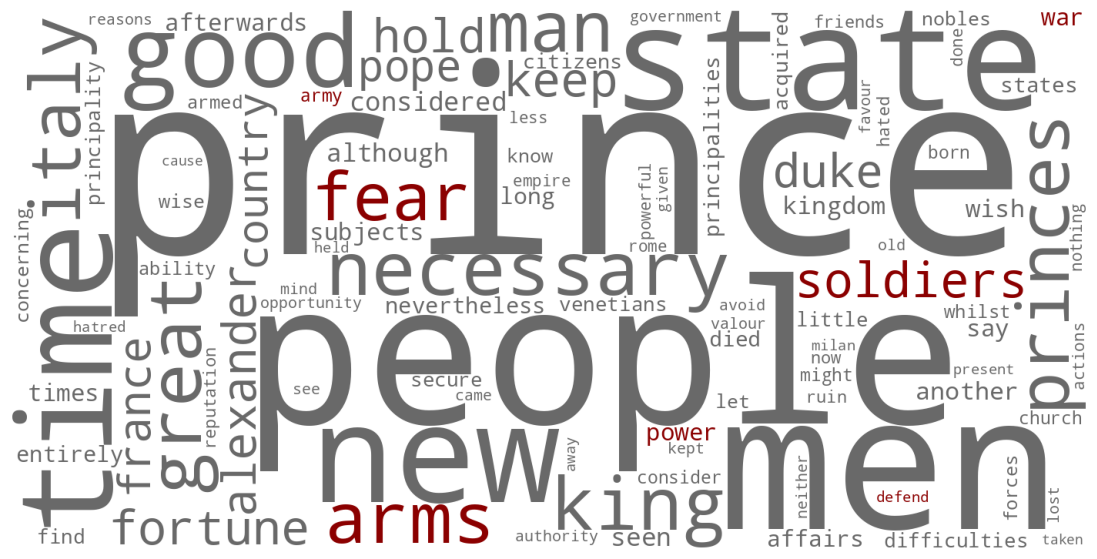

In [15]:
cloud_text = prince.lower().replace("’", "'")

wc = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    max_words=100,
    stopwords=my_stops,
    collocations=False,
    normalize_plurals=False,
    random_state=42
).generate(cloud_text)

wc.recolor(color_func=color_function)

plt.figure(figsize=(14, 7))
plt.imshow(wc)
plt.axis("off")
plt.show()

### 5. Check the 20 biggest words
`wc.words_` stores the words of the cloud ordered from the most to the least frequent.

In [16]:
print(list(wc.words_)[:20])

['prince', 'people', 'men', 'state', 'new', 'time', 'good', 'necessary', 'great', 'king', 'princes', 'arms', 'italy', 'man', 'fear', 'soldiers', 'fortune', 'keep', 'hold', 'alexander']


### 6. Interpretation – what the word cloud shows

**1. The book speaks to one person: the ruler.** *Prince* is by far the biggest word. *The Prince* is a "mirror for princes", an advice book dedicated to Lorenzo de' Medici, so nearly every argument is about what *the prince* should or should not do.

**2. The subject is power, not morality.** Around *prince* we see *state*, *power*, *force*, *hold*, *keep*, *kingdom* and *subjects*. The book is mainly about how a ruler gets a state and, above all, how he **keeps** it. Moral vocabulary is rare; *good* is visible, but in the text it usually means practical goodness (good arms, good laws), not Christian virtue.

**3. War and military power.** The dark red words (*arms*, *soldiers*, *war*, *force*, *power*, *fear*) take a large part of the cloud. This matches chapters XII–XIV, where Machiavelli argues that a prince needs his own army instead of mercenaries, and that "good laws and good arms" are the foundation of every state. Machiavelli had himself organised the Florentine militia.

**4. Fear and fortune.** *Fear* is a large word, and in Task 1 *feared* and *hated* occurred more often than *loved* – the theme of chapter XVII. *Fortune* is also visible: Machiavelli repeatedly contrasts *fortuna* (luck, circumstances) with the ruler's own *virtù* (here translated as *ability*), especially in chapter XXV.

**5. A historical method.** Many names appear: *Italy*, *France*, *pope*, *duke*, *king*, *Alexander*, *Romans*. Machiavelli argues with examples from ancient history and from Italy of his own time – the French invasions, Pope Alexander VI, Duke Valentino (Cesare Borgia). Words like *example* and *seen* show the same habit. *Italy* also points to the last chapter, the call to free Italy "from the barbarians".

**6. A practical tone.** *Necessary* is one of the most frequent words: Machiavelli keeps saying what a prince must do because circumstances force him to.

**Limitations**
- A word cloud shows only how often a word appears, not in which context.
- One word can mean different things: *Alexander* is both Alexander the Great and Pope Alexander VI.
- The words come from a 1908 English translation, not from Machiavelli's Italian.
- The result depends on my choices: which stopwords I removed and which part of the file I kept. Without cutting out the other works in the file, *Castruccio* (from *The Life of Castruccio Castracani*) would have been one of the biggest words.